# SAE "Analyse automatique de données" -- Notebook 2 : classification binaire

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du classifieur choisi (k plus proche voisin ou arbre de décision) pour effectuer une classification binaire des avis ;
2. [Bonus] Effectuer des expérimentations supplémentaires avec d'autres classifieurs (l'autre classifieur vu en cours ou d'autres classifieurs de `scikit-learn`) ;
3. Rédiger une synthèse pour justifier des pré-traitements effectués, du choix du regroupement des notes pour obtenir des classes binaires et des valeurs des paramètres obtenus pour vos classifieurs. Vous concluerez sur le meilleur choix des pré-traitements, des classes binaires et des paramètres de votre ou vos classifieurs.


Faites attention à la prise en compte du déséquilibre que vous pourriez avoir entre vos deux classes, en termes de nombre d'avis dans chacune des classes. 
Vous pouvez notamment utiliser le module python `imbalanced-learn` pour tester différentes manières de gérer les déséquilibres entre classes.
	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.



## Modules python utilisés

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

## 1. Classification binaire avec le classifieur ...

Processeur : passthrough
Les meilleurs paramètres à utiliser sont :  {'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_split': 15, 'classifier__splitter': 'random'}
Meilleur score de validation : 0.60544 
Rapport de classification pour DecisionTree 
                    precision    recall  f1-score   support

Avis défavorables       0.64      0.49      0.55      1582
  Avis favorables       0.59      0.72      0.65      1582

         accuracy                           0.61      3164
        macro avg       0.61      0.61      0.60      3164
     weighted avg       0.61      0.61      0.60      3164



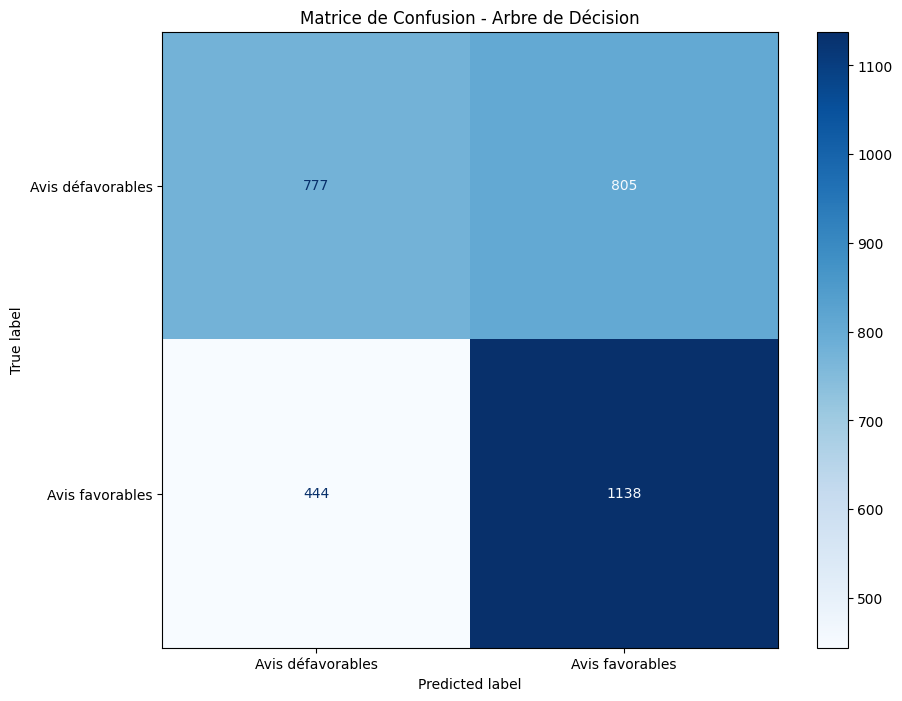

In [13]:
# --- Récupération des données du notebook 1 ---

#Df d'apprentissage
x_train = pd.read_csv('data/train_test/x_train.csv',  index_col=0)
y_train = pd.read_csv('data/train_test/y_train.csv',  index_col=0)

#Df de test
x_test = pd.read_csv('data/train_test/x_test.csv',  index_col=0)
y_test = pd.read_csv('data/train_test/y_test.csv',  index_col=0)

#Transformation de la colonne rating en 0 pour avis défavorable ou 1 pour avis favorable
#Nous considérons que une note inférieure ou égale à 3 est négative.
y_train['rating'] = (y_train['rating'] > 3).astype(int)
y_test['rating'] = (y_test['rating'] > 3).astype(int)

# --- Utilisation du classifieur DecisionTree ---

# On défini les différentes transformeurs 
processeur = ColumnTransformer(
    remainder='passthrough',
    transformers=[
        ('review', TfidfVectorizer(), 'text_'),
        ('category', OneHotEncoder(), ['category']),
        ('label', OneHotEncoder(), ['label'])
    ]
)

print(f"Processeur : {processeur.remainder}")

model_tree = Pipeline([
    ('preprocessor', processeur),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

model_tree.fit(x_train,y_train)

# --- Recherche des meilleurs hypermaramètres --- 

parametre_grid = {"classifier__max_depth": [10, 20, 50, None], 
                  "classifier__min_samples_split": [5, 15, 20], 
                  "classifier__criterion" : ['gini', 'entropy'], 
                  "classifier__splitter" : ['best', 'random']}

grid_search = GridSearchCV(estimator= model_tree, param_grid=parametre_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(x_train, y_train)

print("Les meilleurs paramètres à utiliser sont : ", grid_search.best_params_) 
print(f"Meilleur score de validation : {grid_search.best_score_:.5f} ")

# --- Test sur le modèle avec les meilleurs paramètres --- 

best_model = grid_search.best_estimator_
predictions = best_model.predict(x_test)

name_classe = ['Avis défavorables', 'Avis favorables']

print("Rapport de classification pour DecisionTree \n", classification_report(y_test, predictions, target_names=name_classe))

# --- Création de la matrice de confusion  --- 

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions,
    display_labels=name_classe,
    cmap='Blues',
    ax=ax
)
plt.title("Matrice de Confusion - Arbre de Décision")
plt.show()


## [Bonus] 2. Utilisation d'autres classifieurs binaires 

c:\Users\Fbill\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neighbors\_classification.py:243: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


Les meilleurs paramètres pour le classifieur KNN à utiliser sont :  {'classifier__metric': 'euclidean', 'classifier__n_neighbors': 15, 'classifier__weights': 'distance'}
Meilleur score de validation pour le classifieur KNN : 0.58868 
Rapport de classification pour KNN 
                    precision    recall  f1-score   support

Avis défavorables       0.58      0.59      0.59      1582
  Avis favorables       0.58      0.58      0.58      1582

         accuracy                           0.58      3164
        macro avg       0.58      0.58      0.58      3164
     weighted avg       0.58      0.58      0.58      3164



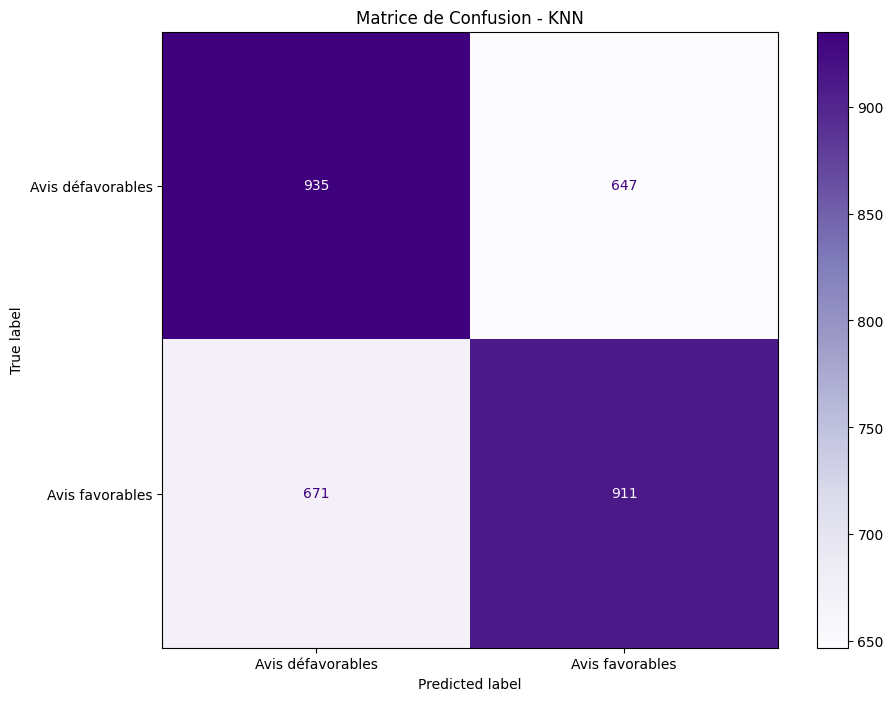

In [14]:
# --- Utilisation du classifieur KNN ---

model_tree_KNN = Pipeline([
    ('preprocessor', processeur),
    ('classifier', KNeighborsClassifier())
])

# --- Recherche des meilleurs hypermaramètres --- 

parametre_grid_KNN = {"classifier__n_neighbors" : [5, 10, 15],
                      "classifier__weights": ['uniform', 'distance'], 
                      "classifier__metric": ['euclidean', 'manhattan']}

grid_knn = GridSearchCV(model_tree_KNN, parametre_grid_KNN, cv=5, scoring='accuracy', n_jobs=-1)
grid_knn.fit(x_train, y_train)

print("Les meilleurs paramètres pour le classifieur KNN à utiliser sont : ", grid_knn.best_params_) 
print(f"Meilleur score de validation pour le classifieur KNN : {grid_knn.best_score_:.5f} ")

# --- Test sur le modèle avec les meilleurs paramètres --- 

best_model_KNN = grid_knn.best_estimator_
predictions_KNN = best_model_KNN.predict(x_test)

print("Rapport de classification pour KNN \n", classification_report(y_test, predictions_KNN, target_names=name_classe))

# --- Création de la matrice de confusion  --- 

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions_KNN, 
    display_labels=name_classe,
    cmap='Purples',
    ax=ax
)
plt.title("Matrice de Confusion - KNN")
plt.show()

c:\Users\Fbill\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Les meilleurs paramètres pour le classifieur Random Forest à utiliser sont :  {'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}
Meilleur score de validation pour le classifieur Random Forest : 0.68100 
Rapport de classification pour Random Forest 
                     precision    recall  f1-score   support

Avis défavorables       0.67      0.71      0.69      1582
  Avis favorables       0.69      0.65      0.67      1582

         accuracy                           0.68      3164
        macro avg       0.68      0.68      0.68      3164
     weighted avg       0.68      0.68      0.68      3164



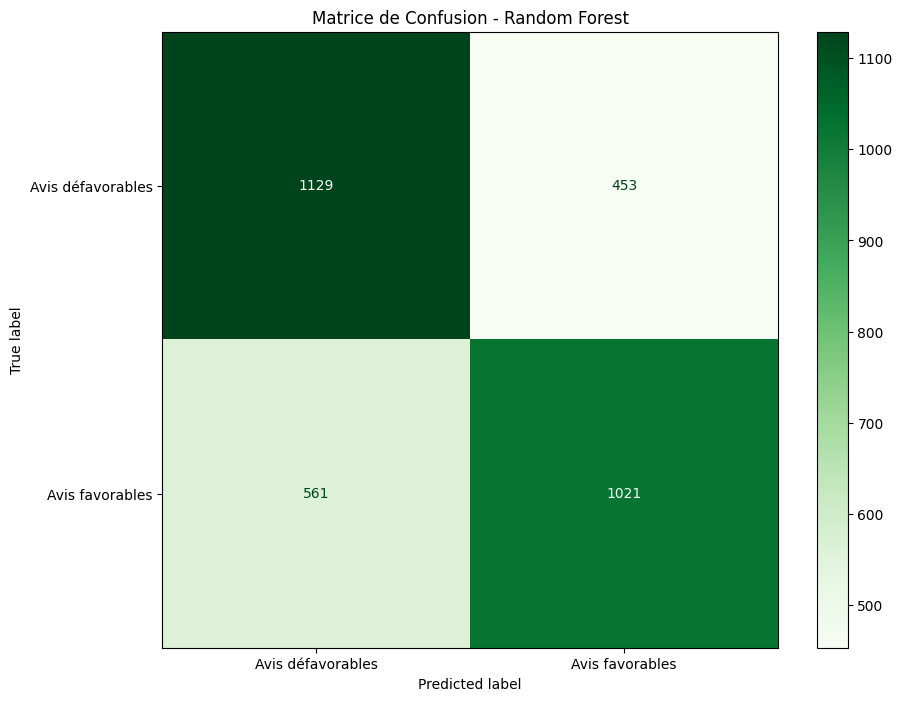

In [15]:
# --- Utilisation du classifieur Random Forest ---

model_tree_rf = Pipeline([
    ('preprocessor', processeur),
    ('classifier', RandomForestClassifier())
])

# --- Recherche des meilleurs hypermaramètres --- 

parametre_grid_rf = { 'classifier__n_estimators': [100, 200, 500],
                  "classifier__min_samples_split": [5, 10], 
                  "classifier__min_samples_leaf": [1, 2]}

grid_rf = GridSearchCV(model_tree_rf, parametre_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(x_train, y_train)

print("Les meilleurs paramètres pour le classifieur Random Forest à utiliser sont : ", grid_rf.best_params_) 
print(f"Meilleur score de validation pour le classifieur Random Forest : {grid_rf.best_score_:.5f} ")

# --- Test sur le modèle avec les meilleurs paramètres --- 

best_model_rf = grid_rf.best_estimator_
predictions_rf = best_model_rf.predict(x_test)

print("Rapport de classification pour Random Forest \n ", classification_report(y_test, predictions_rf, target_names=name_classe))

# --- Création de la matrice de confusion  --- 

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions_rf, 
    display_labels=name_classe,
    cmap='Greens',
    ax=ax
)
plt.title("Matrice de Confusion - Random Forest")
plt.show()

c:\Users\Fbill\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Les meilleurs paramètres pour le classifieur Logistic Regression à utiliser sont :  {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
Meilleur score de validation pour le classifieur Logistic Regression : 0.69009 
Rapport de classification pour Logistic Regression 
                     precision    recall  f1-score   support

Avis défavorables       0.69      0.69      0.69      1582
  Avis favorables       0.69      0.69      0.69      1582

         accuracy                           0.69      3164
        macro avg       0.69      0.69      0.69      3164
     weighted avg       0.69      0.69      0.69      3164



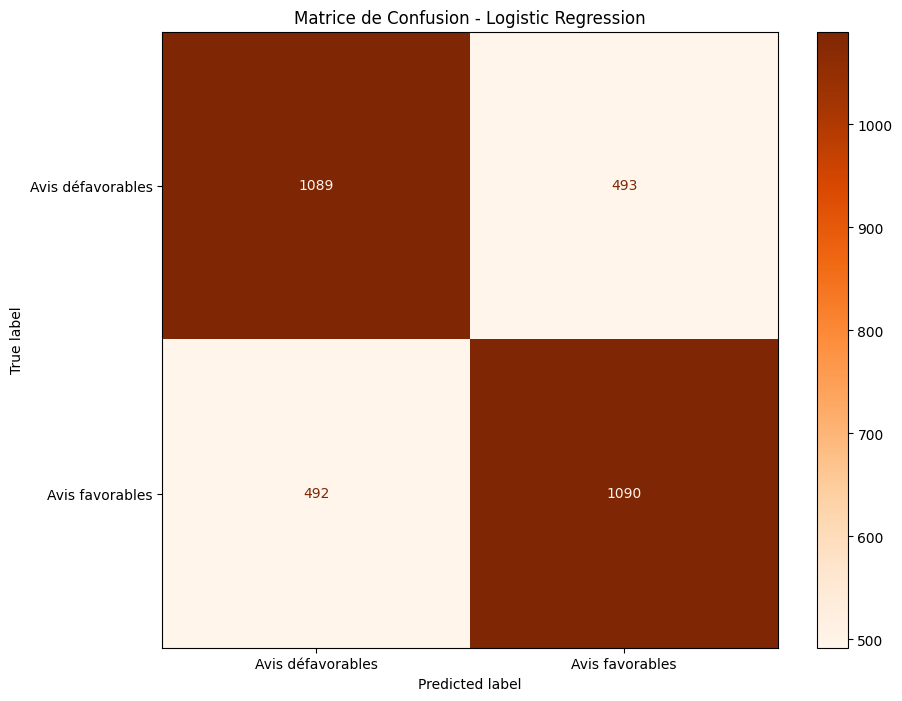

In [16]:
# --- Utilisation du classifieur Logistic Regression ---

model_tree_lr = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LogisticRegression())
])

# --- Recherche des meilleurs hypermaramètres --- 

parametre_grid_lr = { "classifier__C": [0.1, 1, 10], 
                    "classifier__solver": ['lbfgs', 'liblinear', 'newton-cg']}

grid_lr = GridSearchCV(model_tree_lr, parametre_grid_lr, cv=5, scoring='accuracy', n_jobs=-1)
grid_lr.fit(x_train, y_train)

print("Les meilleurs paramètres pour le classifieur Logistic Regression à utiliser sont : ", grid_lr.best_params_) 
print(f"Meilleur score de validation pour le classifieur Logistic Regression : {grid_lr.best_score_:.5f} ")

# --- Test sur le modèle avec les meilleurs paramètres --- 

best_model_lr = grid_lr.best_estimator_
predictions_lr = best_model_lr.predict(x_test)

print("Rapport de classification pour Logistic Regression \n ", classification_report(y_test, predictions_lr, target_names=name_classe))

# --- Création de la matrice de confusion  --- 

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions_lr, 
    display_labels=name_classe,
    cmap='Oranges',
    ax=ax
)
plt.title("Matrice de Confusion - Logistic Regression")
plt.show()

## 3. Synthèse des expérimentations et des résultats obtenus